# Scratch: NGC 1399 investigation

Throwaway notebook for poking at the trimmed cube and the representative-bin spectra directly -- not part of the example-notebook sequence.

In [1]:
from __future__ import annotations
import warnings

import numpy as np
import matplotlib.pyplot as plt

from kinextract import load_muse_cube, white_light_image, extract_aperture_spectrum

CUBE_PATH = "muse_download/ngc1399_cube_wfm_caii.fits"
Z = 1442.0 / 299792.458  # NGC 1399 systemic velocity ~1442 km/s (NED weighted mean)

In [2]:
cube = load_muse_cube(CUBE_PATH)
ny, nx = cube.shape
print(f"cube: {cube.flux.shape} (n_wave, ny, nx), pixel_scale={cube.pixel_scale}\"")
print(f"wave range: {cube.wave.min():.1f}-{cube.wave.max():.1f} A (observed frame)")

cube: (800, 831, 831) (n_wave, ny, nx), pixel_scale=0.20000000000000015"
wave range: 8001.0-8999.8 A (observed frame)


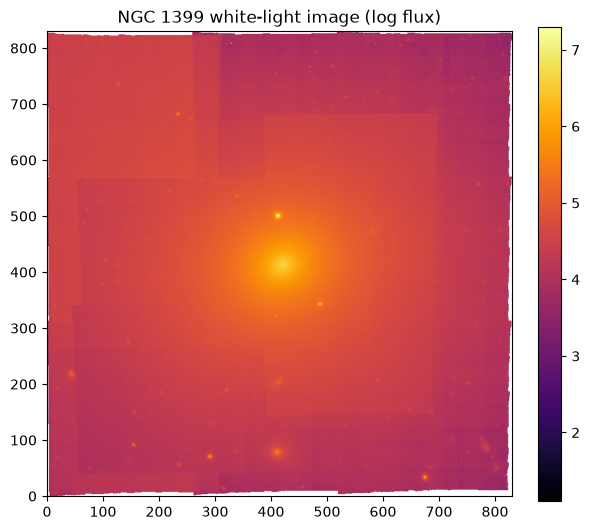

In [3]:
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    white_light = white_light_image(cube)

with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)

fig, ax = plt.subplots(figsize=(6, 5.5))
im = ax.imshow(log_white_light, origin="lower", cmap="inferno")
ax.set_title("NGC 1399 white-light image (log flux)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## The single brightest (nucleus) spaxel

This is the spaxel `04_template_calibration.ipynb`'s own binning picks as the field center -- and the one whose extracted spectrum showed a deep, narrow (~15A) dip at rest-frame ~8500A, much deeper than the normal CaII line depth seen in every other aperture.

In [10]:
with warnings.catch_warnings():
    warnings.filterwarnings("ignore")
    signal_map = np.nanmedian(cube.flux, axis=0)
    noise_map = np.nanmedian(cube.error, axis=0)
good = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)
search_region_mask = np.zeros((ny, nx), dtype=bool)
xmin, xmax = 350, 500
ymin, ymax = 350, 500
by, bx = np.unravel_index(np.nanargmax(np.where(good, signal_map, np.nan)), signal_map.shape)
print(f"brightest spaxel: (y={by}, x={bx})")

spaxel_mask = np.zeros((ny, nx), dtype=bool)
spaxel_mask[by, bx] = True
wave_obs, flux_obs, error_obs = extract_aperture_spectrum(cube, spaxel_mask)
wave_rest = wave_obs / (1.0 + Z)

brightest spaxel: (y=499, x=412)


In [24]:
mask.shape[0]

831

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True]], shape=(831, 831))

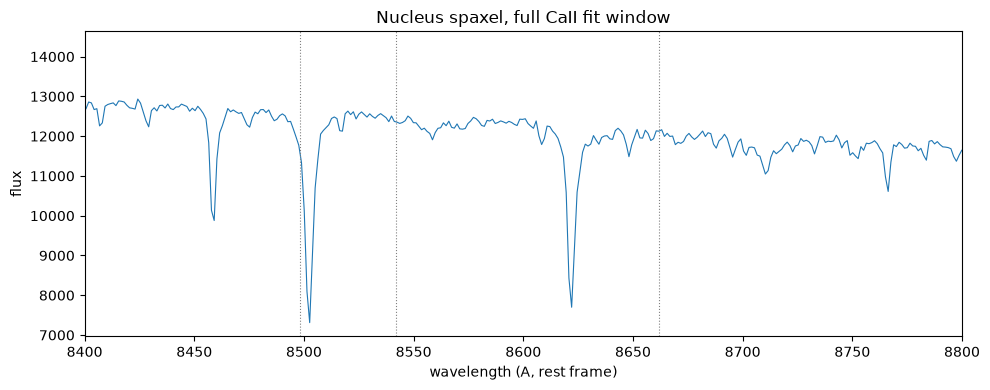

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wave_rest, flux_obs, lw=0.8)
for line in (8498, 8542, 8662):
    ax.axvline(line, color="gray", ls=":", lw=0.8)
ax.set_xlim(8400, 8800)
ax.set_xlabel("wavelength (A, rest frame)"); ax.set_ylabel("flux")
ax.set_title("Nucleus spaxel, full CaII fit window")
plt.tight_layout(); plt.show()

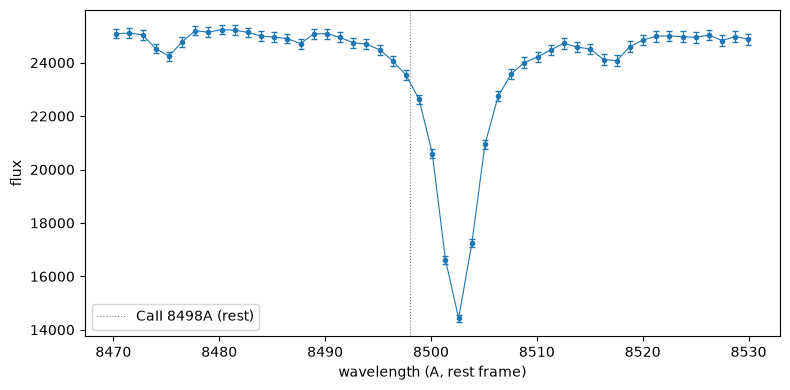

In [6]:
# zoom on the ~8500A feature
in_zoom = (wave_rest > 8470) & (wave_rest < 8530)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(wave_rest[in_zoom], flux_obs[in_zoom], yerr=error_obs[in_zoom], fmt="o-", ms=3, lw=0.8, capsize=2)
ax.axvline(8498, color="gray", ls=":", lw=0.8, label="CaII 8498A (rest)")
ax.set_xlabel("wavelength (A, rest frame)"); ax.set_ylabel("flux")
ax.legend(); plt.tight_layout(); plt.show()

## Compare against a neighboring (non-central) spaxel or small aperture

Swap in whatever comparison you want here -- e.g. a spaxel just off-center, or a small aperture average, to see whether the deep dip is isolated to the single brightest pixel or extends further.